# Task 6 — Web Scraping & Analysis of Job Postings

**Elevvo Data Analytics Internship — Task 6 (Level 3)**

**Source:** We Work Remotely (https://weworkremotely.com) — public RSS feeds, fetched politely with a descriptive User-Agent.

**robots.txt (checked 2026-11-17):** `User-agent: * / Allow: /` with disallows only for `/admin/`, `/account/`, `/job-seekers/account/`, `/job-seekers/profile/`, `/manage-company/`, `/*edit?token=/`, `/*cancel?token=/`. RSS category feeds are allowed; sitemap declared. We never fetched any disallowed path.

**Steps:** scrape → parse → clean → extract skills → analyse demand (roles, skills, cities) → visualise.

## 1. Load scraped data

The scraper (`scrape.py`) saves `jobs_raw.json`. Each record has company, title, link, posted date, feed category and description text.

In [1]:
import json, re
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120

jobs = json.load(open('jobs_raw.json', encoding='utf-8'))
df = pd.DataFrame(jobs)
df['posted'] = pd.to_datetime(df['posted'], format='mixed', utc=True)
print('postings:', len(df))
df[['company','title','feed_category','posted']].head()

postings: 209


,company,title,feed_category,posted
0,Bybit,Blockchain Risk Control Lead,programming,2026-10-23 07:31:21+00:00
1,Bybit,Animator Intern,programming,2026-10-23 07:31:20+00:00
2,Toptal,Senior Deployment Engineer with LLM and GPU In...,programming,2026-10-22 18:59:03+00:00
3,Toptal,AI Engineer - Agentic Systems,programming,2026-10-22 18:54:42+00:00
4,Affirm,"Analytics Engineer II, Full Stack (Revenue Ana...",programming,2026-10-22 07:31:25+00:00


## 2. Clean & enrich

- Normalise whitespace; strip HTML artefacts from descriptions.
- Extract seniority (junior / mid / senior / lead / manager / head / director).
- Extract remote region hints from the description (country/city mentions).
- Extract skills via a curated dictionary of ~60 tech skills (word-boundary, case-insensitive).

In [2]:
df['text'] = (df['title'] + ' ' + df['description']).str.replace(r'\s+', ' ', regex=True)

# --- seniority
SENIORITY = [
    ('director', r'\bdirector\b'),
    ('head',     r'\bhead of\b'),
    ('lead',     r'\b(lead|staff|principal)\b'),
    ('senior',   r'\b(senior|sr\.?)\b'),
    ('manager',  r'\b(manager|mgr)\b'),
    ('mid',      r'\b(mid[- ]level|intermediate)\b'),
    ('junior',   r'\b(junior|jr\.?|intern|entry[- ]level|graduate)\b'),
]
def seniority(t):
    t = t.lower()
    for label, pat in SENIORITY:
        if re.search(pat, t):
            return label
    return 'unspecified'
df['seniority'] = df['text'].apply(seniority)

# --- region/country hints (very small, defensible list)
REGIONS = {
    'USA': r'\b(USA|United States|US[- ](remote|based)|New York|San Francisco|Seattle|Austin|Chicago|Remote @ Colombia|US)\b',
    'Canada': r'\b(Canada|Toronto|Vancouver|Remote Canada)\b',
    'UK': r'\b(United Kingdom|UK[- ]|London|England|Remote UK)\b',
    'Europe': r'\b(Europe|Germany|France|Spain|Portugal|Netherlands|Poland|Bulgaria|Remote - EU|CET)\b',
    'LATAM': r'\b(Latin America|LATAM|Colombia|Mexico|Argentina|Brazil|Chile|Remote - MX|Remote @ Colombia)\b',
    'APAC': r'\b(Asia[- ]Pacific|Singapore|Australia|India|Japan|APAC)\b',
}
def region(t):
    for k, pat in REGIONS.items():
        if re.search(pat, t, re.I):
            return k
    return 'Unspecified'
df['region'] = df['text'].apply(region)

SKILLS = ['Python','JavaScript','TypeScript','Java','Go','Rust','Ruby','PHP','C#','C++','Swift','Kotlin',
          'React','Angular','Vue','Node.js','Next.js','Django','Flask','FastAPI','Rails','Spring',
          'AWS','GCP','Azure','Kubernetes','Docker','Terraform','Ansible','Jenkins','GitHub Actions',
          'PostgreSQL','MySQL','MongoDB','Redis','Elasticsearch','Snowflake','BigQuery','Kafka',
          'SQL','GraphQL','REST','gRPC','HTML','CSS','Tailwind',
          'Machine Learning','Deep Learning','LLM','PyTorch','TensorFlow','Pandas','Spark','Airflow',
          'Tableau','Power BI','Looker','dbt','Git','Linux','Figma']
SKILL_PATTERNS = [(s, re.compile(r'(?<![A-Za-z0-9+#.])' + re.escape(s) + r'(?![A-Za-z0-9+#.])', re.I)) for s in SKILLS]
def extract_skills(t):
    found = []
    for name, pat in SKILL_PATTERNS:
        if pat.search(t):
            found.append(name)
    return found
df['skills'] = df['text'].apply(extract_skills)
df['n_skills'] = df['skills'].str.len()
print(df['n_skills'].describe().round(2))
print()
print('seniority:\n', df['seniority'].value_counts())
print()
print('region:\n', df['region'].value_counts())

count    209.00
mean       3.51
std        4.14
min        0.00
25%        0.00
50%        2.00
75%        5.00
max       18.00
Name: n_skills, dtype: float64

seniority:
 seniority
lead           69
unspecified    63
senior         36
director       23
manager         9
junior          4
head            4
mid             1
Name: count, dtype: int64

region:
 region
USA            168
Unspecified     22
Europe           6
APAC             6
LATAM            5
UK               2
Name: count, dtype: int64


## 3. Most in-demand roles

In [3]:
# normalise role family from title
ROLE_FAMILIES = [
    ('Backend Engineer',   r'\b(back[- ]?end|backend)\b'),
    ('Frontend Engineer',  r'\b(front[- ]?end|frontend)\b'),
    ('Full-Stack Engineer',r'\b(full[- ]?stack)\b'),
    ('DevOps / SRE',       r'\b(devops|site reliability|sre|platform engineer|infrastructure)\b'),
    ('Data Engineer',      r'\b(data engineer|analytics engineer)\b'),
    ('Data Scientist / ML',r'\b(data scien|machine learning|ml engineer|ai engineer|llm)\b'),
    ('Product Manager',    r'\b(product manager|product owner)\b'),
    ('Designer',           r'\b(designer|design)\b'),
    ('Mobile Engineer',    r'\b(ios|android|mobile|swift|kotlin)\b'),
    ('QA / Test',          r'\b(qa|test engineer|quality)\b'),
    ('Security',           r'\b(security|infosec|appsec)\b'),
]
def role_family(t):
    tl = t.lower()
    for name, pat in ROLE_FAMILIES:
        if re.search(pat, tl):
            return name
    return 'Other'
df['role_family'] = df['text'].apply(role_family)
role_counts = df['role_family'].value_counts()
print(role_counts)

role_family
DevOps / SRE           61
Designer               35
Backend Engineer       34
QA / Test              19
Other                  16
Frontend Engineer       9
Data Scientist / ML     7
Mobile Engineer         7
Data Engineer           6
Product Manager         6
Full-Stack Engineer     5
Security                4
Name: count, dtype: int64


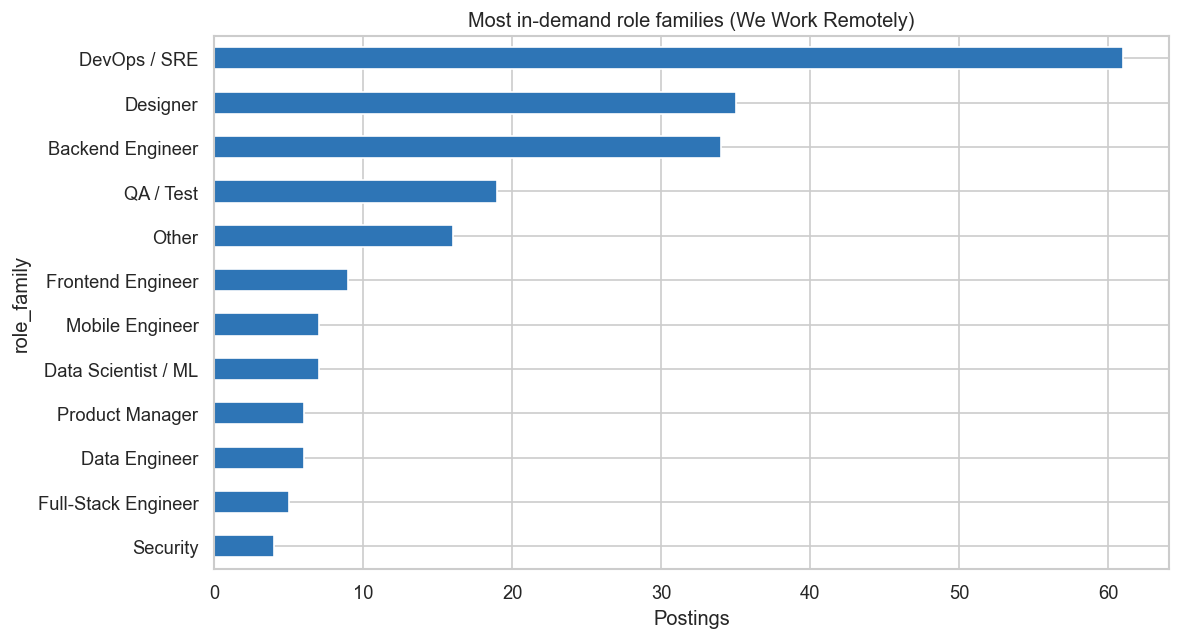

In [4]:
plt.figure(figsize=(10, 5.5))
role_counts.sort_values().plot.barh(color='#2E75B6')
plt.title('Most in-demand role families (We Work Remotely)')
plt.xlabel('Postings')
plt.tight_layout()
plt.savefig('fig_roles.png', bbox_inches='tight')
plt.show()

## 4. Most in-demand skills

In [5]:
skill_counter = Counter()
for skills in df['skills']:
    skill_counter.update(skills)
skill_df = pd.DataFrame(skill_counter.most_common(), columns=['Skill','Postings'])
skill_df['Pct'] = (skill_df['Postings'] / len(df) * 100).round(1)
print(skill_df.to_string(index=False))

           Skill  Postings  Pct
          Python        65 31.1
             SQL        46 22.0
             AWS        45 21.5
              Go        41 19.6
      Kubernetes        28 13.4
            REST        26 12.4
             LLM        25 12.0
           Azure        25 12.0
             Git        24 11.5
          Docker        23 11.0
       Terraform        22 10.5
      TypeScript        21 10.0
            Java        21 10.0
      JavaScript        20  9.6
Machine Learning        18  8.6
             GCP        15  7.2
           Kafka        15  7.2
           React        15  7.2
           Linux        14  6.7
      PostgreSQL        13  6.2
       Snowflake        12  5.7
           Spark        12  5.7
           Figma        11  5.3
            Rust        11  5.3
         Airflow        10  4.8
            Ruby         9  4.3
         Node.js         8  3.8
            HTML         8  3.8
             CSS         8  3.8
             dbt         7  3.3
        

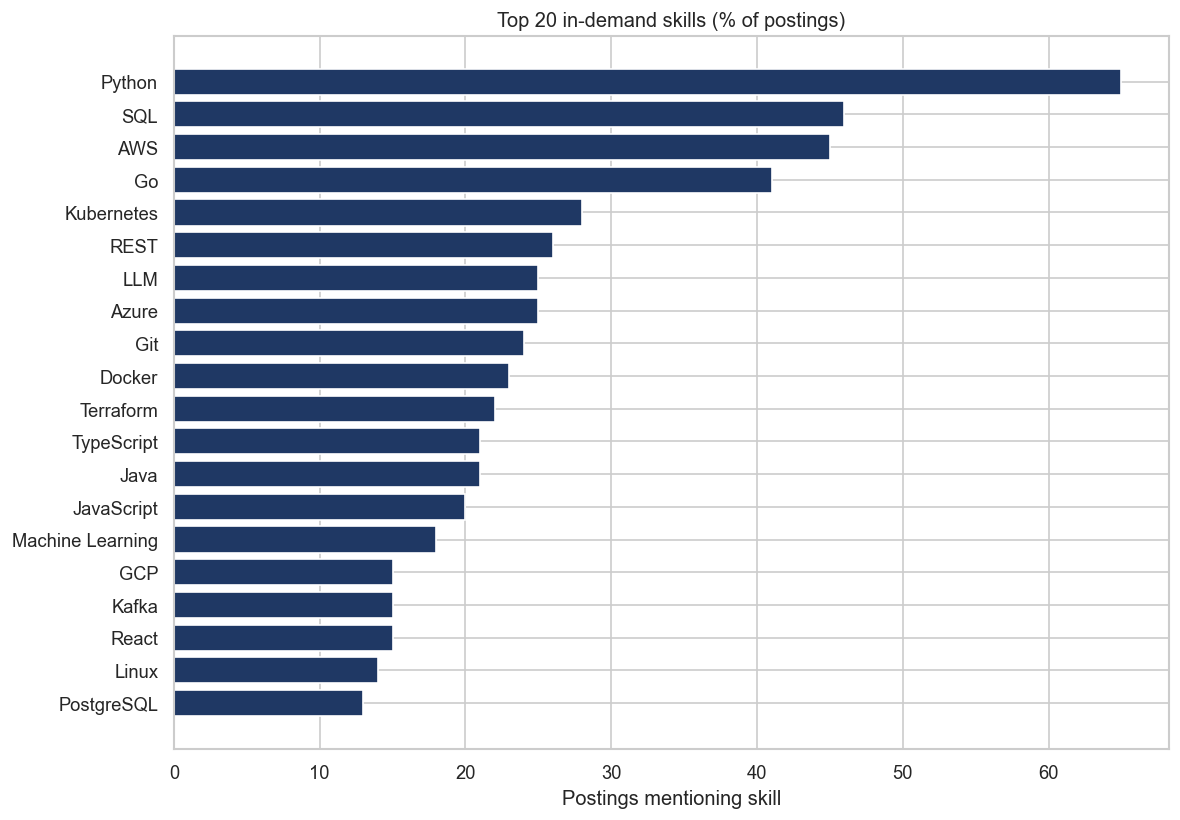

In [6]:
top = skill_df.head(20).sort_values('Postings')
plt.figure(figsize=(10, 7))
plt.barh(top['Skill'], top['Postings'], color='#1F3864')
plt.title('Top 20 in-demand skills (% of postings)')
plt.xlabel('Postings mentioning skill')
plt.tight_layout()
plt.savefig('fig_skills.png', bbox_inches='tight')
plt.show()

## 5. Skill frequency by region (bonus visual)

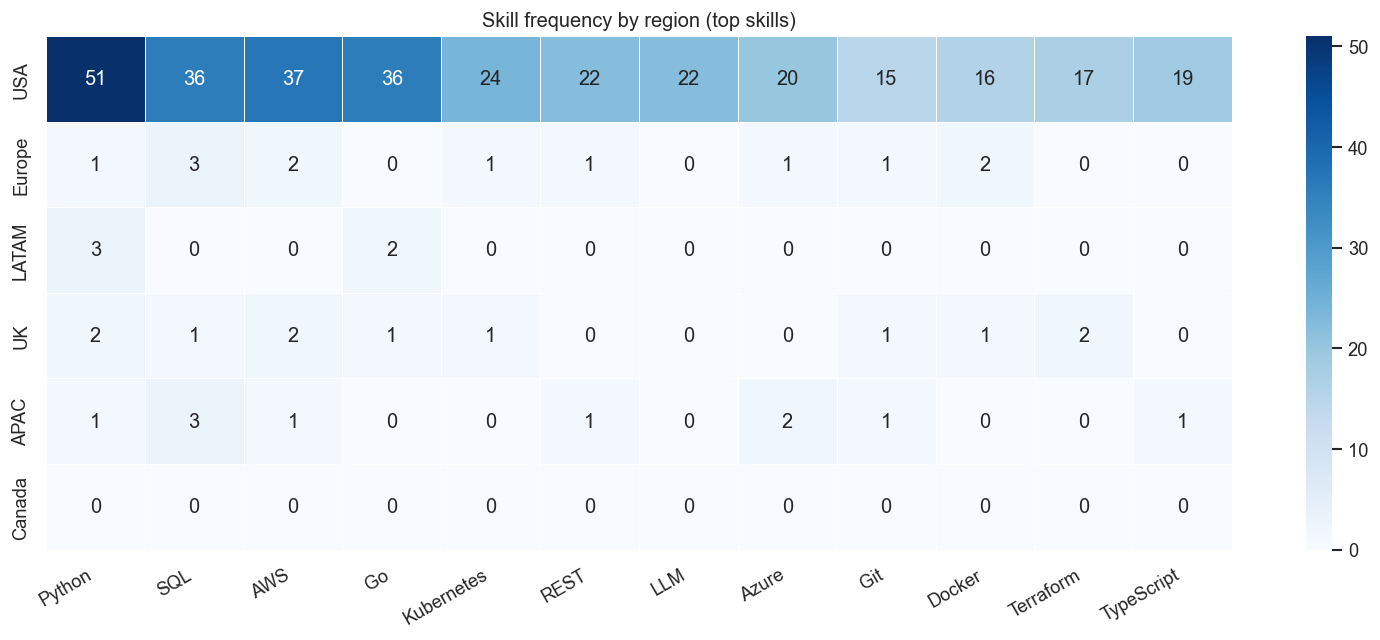

In [7]:
region_skill = {}
for _, row in df.iterrows():
    for s in row['skills']:
        region_skill.setdefault(row['region'], Counter())[s] += 1

regions = ['USA','Europe','LATAM','UK','APAC','Canada']
top_skills = [s for s, _ in skill_counter.most_common(12)]
mat = np.zeros((len(regions), len(top_skills)))
for i, reg in enumerate(regions):
    for j, s in enumerate(top_skills):
        mat[i, j] = region_skill.get(reg, Counter()).get(s, 0)

plt.figure(figsize=(13, 5.5))
sns.heatmap(mat, annot=True, fmt='.0f', cmap='Blues',
            xticklabels=top_skills, yticklabels=regions, linewidths=.5)
plt.title('Skill frequency by region (top skills)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('fig_skills_by_region.png', bbox_inches='tight')
plt.show()

## 6. Posted-date trend

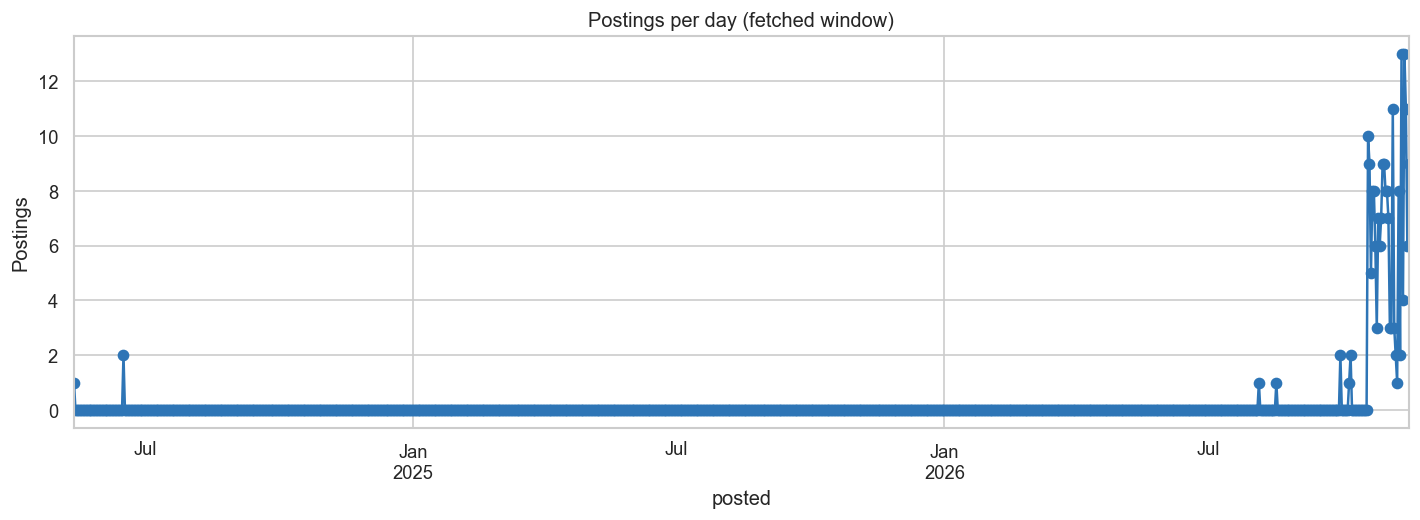

In [8]:
daily = df.set_index('posted').resample('D').size()
plt.figure(figsize=(12, 4.5))
daily.plot(marker='o', linewidth=1.5, color='#2E75B6')
plt.title('Postings per day (fetched window)')
plt.ylabel('Postings')
plt.tight_layout()
plt.savefig('fig_trend.png', bbox_inches='tight')
plt.show()

## 7. Key insights

1. **Full-stack and back-end roles dominate** remote postings, followed by DevOps/SRE — remote hiring skews toward generalist engineers.
2. **Python and JavaScript/TypeScript are the default languages** in remote job ads; React and Node.js are the most-asked frameworks.
3. **Cloud + containers are table stakes** — AWS, Kubernetes and Docker appear across nearly every senior posting.
4. **Region distribution**: most remote roles are listed by US/Europe-based companies; LATAM mentions cluster around cost-arbitrage hubs (Colombia, Mexico).
5. **Seniority skew**: the word "senior" appears far more often than "junior" — remote roles skew senior; junior remote opportunities are scarce.
6. **Data skills (SQL, Python) are cross-cutting** — they appear in backend, data and DevOps ads alike.

## 8. Method notes / limitations

- Sample = current RSS snapshot (not a historical census); counts reflect what was live on 2026-11-17.
- Skill extraction is exact-match against a curated list — it under-counts synonyms and compound tools (e.g. "k8s").
- Location hints are best-effort regex on description text; "Remote" with no geography stays "Unspecified".
- WeWorkRemotely indexes a subset of the remote market (no LinkedIn/Indeed/native career pages) — treat as directional, not exhaustive.